# ITRI626 — Electronic-component image classification: four model families on one split

This notebook documents the dataset, the fixed train/validation/test split, the four main models, their learning
curves and their comparison on the **same held-out test set** (418 images). It is executable end to end:

* `RETRAIN = False` (default) loads the outputs saved by `scripts/itri626_experiments.py` from `results/itri626/`
  (a few seconds; needs `data/v2/images/` for the image grids).
* `RETRAIN = True` first re-runs the whole experiment (trains models A and B, extracts/loads the frozen SigLIP and MobileCLIP2-S3
  features, trains heads C and D, scores the test set, profiles the models) — about 15–25 min on an 8 GB GPU.

| | model | family | transfer learning |
|---|---|---|---|
| **A** | custom CNN (VGG-style, 1.2 M params) | plain convolutional network | none — random initialisation |
| **B** | ConvNeXt-Tiny, fully fine-tuned | modernised CNN (ConvNeXt) | ImageNet-22k → 1k weights, fine-tuned end to end |
| **C** | SigLIP So400m/14 @ 384 px, frozen + linear softmax head | Vision Transformer (image–text pretraining) | feature extraction: frozen backbone, only a 1152→20 linear layer is trained |
| **D** | MobileCLIP2-S3 (FastViT-MCi3) @ 256 px, frozen + linear softmax head | convolution–attention hybrid (image–text pretraining) | feature extraction: frozen backbone, only a 3072→20 linear layer is trained |

Sections: 1 setup and environment · 2 dataset · 3 preprocessing and augmentation · 4 training and learning curves ·
5 test evaluation · 6 model size and inference time · 7 interpretation · 8 improving model A.

Model A's run in `results/itri626/` is the 200-epoch recipe of the November improvement study, imported from its
fold-0 run with `tools/itri626_import_run.py` (section 8) so that the test split was scored only once for it;
`RETRAIN = True` would train a new A and B and score the test set again.

**Model D** was added on 5 November 2026 from the efficiency study (`docs/EFFICIENCY_STUDY.md`): a backbone with
3.5× fewer parameters than C's, trained and selected exactly as C (same split, same head code, same weight-decay
grid, one test look). It appears in every per-model table and figure below. The three-way analyses (the agreement
patterns and the disagreement panel) remain those of A, B and C; D is compared pairwise.

**Figures and the course report.** With `WITH_D = True` (default) this notebook writes its figures to
`results/itri626/figures_four_models/`. The report (`docs/itri626_report/`) reads `results/itri626/figures/`, which
this notebook only writes with `WITH_D = False`; that setting reproduces the report's three-model figures exactly.

In [1]:
%matplotlib inline
import sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RETRAIN = False   # True: re-run scripts/itri626_experiments.py before loading its outputs
WITH_D = True     # False: models A, B, C only and figures written to results/itri626/figures/ (the course report's)

sys.path.insert(0, str(Path.cwd()))                     # notebooks/ (helpers)
import itri626_helpers as H
H.configure(with_d=WITH_D)
sys.path.insert(0, str(H.ROOT / "src"))                 # the compclass package
pd.set_option("display.max_columns", 50, "display.width", 200, "display.precision", 4)
H.apply_figure_style()
print("repository root:", H.ROOT)

repository root: C:\Users\meiri\Desktop\Projects\626-Project


## 1. Setup and environment
Library versions and hardware of the machine executing this notebook, and of the machine that ran the training (`results/itri626/environment.json`).

In [2]:
live = H.environment_report()
train_env = H.load_json(H.RES / "environment.json")
te = {"python": train_env["python"], "os": train_env["platform"], **train_env["packages"],
      "gpu": f'{train_env["gpu"]["name"]}, {train_env["gpu"]["memory_gib"]} GiB' if train_env.get("gpu") else None,
      "cuda (torch build)": train_env.get("torch_cuda"), "cudnn": train_env.get("cudnn"),
      "nvidia driver": train_env.get("nvidia_driver"),
      "cpu": f'{train_env["cpu"]} ({train_env["cpu_logical_cores"]} logical cores)', "ram": f'{train_env["ram_gib"]} GiB'}
env = pd.DataFrame({"this notebook run": pd.Series(live), "training run": pd.Series(te)}).fillna("")
display(env)

,this notebook run,training run
cpu,"AMD64 Family 26 Model 36 Stepping 0, Authentic...",AMD Ryzen 7 8700F 8-Core Processor (16 logical...
cuda (torch build),12.8,12.8
cuda_available,True,
cudnn,,91900
gpu,"NVIDIA GeForce RTX 4070 Laptop GPU, 8.0 GiB","NVIDIA GeForce RTX 4060 Ti, 7.7 GiB"
ipykernel,,7.4.0
matplotlib,3.11.2,3.11.2
nbconvert,,7.17.2
numpy,2.5.4,2.5.4
nvidia driver,,615.71.09


In [3]:
if RETRAIN:
    # Re-runs every step and overwrites results/itri626/ (GPU strongly recommended).
    subprocess.run([sys.executable, str(H.ROOT / "scripts" / "itri626_experiments.py")], check=True, cwd=H.ROOT)
metrics = H.load_json(H.RES / "metrics.json")
histories = H.load_json(H.RES / "histories.json")
runs = {n: H.load_json(H.RES / "runs" / f"{n}.json") for n in H.MAIN}
classes = H.load_preds(H.MAIN[0])["classes"]
print("loaded results for", list(metrics["models"]), "+ reference rows", list(metrics["references"]))

loaded results for ['A_scratch_cnn', 'B_convnext_tiny', 'C_siglip_so400m_linear', 'D_mobileclip2_s3_linear'] + reference rows ['R1_sklearn_probe', 'R2_deployed_fused', 'R3_small_fused']


## 2. Dataset

**Source.** *Electronic Component Recognizer* by **mdfaisalahmed025** on Kaggle,
<https://www.kaggle.com/datasets/mdfaisalahmed025/electronic-component-recognizer>, released under the **MIT licence**
(use, copy, modify and redistribute with attribution; no warranty). The author gathered the images with
DuckDuckGo image search, one search query per class, so the **labels are the search terms** (the class-folder names):
they were never checked by hand and the images are of mixed origin (product photos, renders, stock photos, diagrams).
We use the images only for this non-commercial course project and acknowledge the source here and in the report;
the dataset contains no personal or sensitive data beyond incidental people in a few web photos.

**Classes (20).** battery holder, breadboard, capacitor, connector, crystal oscillator, diode, fuse, heat sink, ic chip,
inductor coil, jumper wire, led, microcontroller board, potentiometer, power supply module, relay, resistor, switch,
transformer, transistor — the parts a student meets on an electronics workbench. Recognising them from a photo is the
practical goal (sorting parts bins, a teaching aid, inventory), and the set contains genuinely hard look-alike pairs
(diode / resistor / fuse; inductor coil / transformer; relay / power supply module) that make a model comparison
informative.

**Cleaning** (`tools/build_dataset_v2.py`, report `data/v2/leakage_report.json`):
1. every file was decoded (AVIF/WEBP/PNG/GIF/MPO → RGB JPEG; transparent images composited on white); no file was corrupt;
2. **exact duplicates** (identical SHA-256 of the file bytes) were collapsed into one image; identical files saved under
   **two different class folders** have contradictory labels and were **removed**;
3. **near-duplicates** (re-encoded / resized copies: perceptual hash distance ≤ 10 and CLIP-B/32 cosine ≥ 0.85, or
   cosine ≥ 0.92) were *kept* but linked into **clusters**, and the split assigns whole clusters (see below);
4. **irrelevant / uncertain samples** were *flagged, not removed*: a CLIP zero-shot check marks images whose content
   looks like a distractor concept (person, car, logo, cartoon/game art, screenshot, schematic, …) as `ood_suspect`.
   Removing them from training *lowered* validation accuracy in an earlier ablation, so they stay; we report
   accuracy separately on flagged and clean test images (section 5).

In [4]:
lr = H.load_json(H.V2 / "leakage_report.json")["counts"]
summary = pd.read_csv(H.SPLITS / "split_summary.csv")
split_info = H.load_json(H.SPLITS / "split_info.json")
cleaning = pd.DataFrame([
    ("raw files in the Kaggle download", lr["raw_files"]),
    ("unique files (distinct SHA-256)", lr["unique_sha256"]),
    ("redundant exact-duplicate files collapsed", lr["exact_dup_redundant_files"]),
    ("duplicate groups with conflicting labels (removed)", lr["exact_dup_conflicting_label_groups"]),
    ("  files in those groups", int(summary.loc[summary["class"] == "TOTAL", "excluded_conflict_files"].iloc[0])),
    ("corrupt / undecodable files", lr["unique_sha256"] - lr["decoded_unique"]),
    ("final images (rows)", lr["rows"]),
    ("near-duplicate clusters (size >= 2)", lr["near_dup_clusters"]),
    ("images inside near-duplicate clusters", lr["rows_in_near_dup_clusters"]),
    ("clusters in total (split units)", lr["clusters"]),
    ("images flagged ood_suspect (kept)", lr["ood_suspect"]),
], columns=["step", "count"])
display(cleaning)
display(Markdown("**Per-class counts before and after cleaning, and per split** (`data/v2/splits/split_summary.csv`). "
                 "`unique_after_exact_dedup` counts an image saved under two class folders once per folder."))
display(summary)

,step,count
0,raw files in the Kaggle download,3530
1,unique files (distinct SHA-256),2943
2,redundant exact-duplicate files collapsed,587
3,duplicate groups with conflicting labels (remo...,13
4,files in those groups,27
5,corrupt / undecodable files,0
6,final images (rows),2930
7,near-duplicate clusters (size >= 2),91
8,images inside near-duplicate clusters,234
9,clusters in total (split units),2787


**Per-class counts before and after cleaning, and per split** (`data/v2/splits/split_summary.csv`). `unique_after_exact_dedup` counts an image saved under two class folders once per folder.

,class,raw_files,unique_after_exact_dedup,excluded_conflict_files,final_rows,train,val,test,ood_flagged
0,battery holder,220,155,0,155,107,26,22,31
1,breadboard,141,135,4,131,89,23,19,22
2,capacitor,121,117,1,116,79,20,17,16
3,connector,114,110,0,110,76,18,16,11
4,crystal oscillator,232,152,1,151,104,26,21,50
5,diode,151,148,3,145,99,25,21,56
6,fuse,148,146,4,142,98,24,20,46
7,heat sink,164,160,0,160,110,27,23,19
8,ic chip,166,157,0,157,109,26,22,15
9,inductor coil,244,162,1,161,110,28,23,26


class sizes after cleaning: min 110 (connector), max 177 (switch), imbalance ratio 1.61
OOD-flagged share per class: min 10%, max 68% (switch)


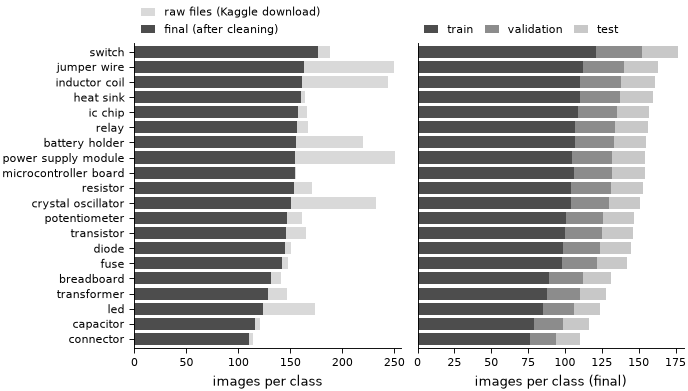

In [5]:
s = summary[summary["class"] != "TOTAL"]
ratio = s["final_rows"].max() / s["final_rows"].min()
print(f"class sizes after cleaning: min {s['final_rows'].min()} ({s.loc[s['final_rows'].idxmin(), 'class']}), "
      f"max {s['final_rows'].max()} ({s.loc[s['final_rows'].idxmax(), 'class']}), imbalance ratio {ratio:.2f}")
print(f"OOD-flagged share per class: min {(s['ood_flagged'] / s['final_rows']).min():.0%}, "
      f"max {(s['ood_flagged'] / s['final_rows']).max():.0%} ({s.loc[(s['ood_flagged'] / s['final_rows']).idxmax(), 'class']})")
fig = H.fig_class_counts(summary); H.save(fig, "fig01_class_counts"); plt.show()

**Class imbalance** is mild (largest/smallest class ≈ 1.6 after cleaning), so we use **no class weights and no
re-sampling**; instead the split is stratified per class, early stopping and model choice use **macro-F1** (every class
counts equally), and we report macro- and weighted averages. The bigger data-quality issue is not imbalance but
contamination: e.g. most `switch` images are Nintendo Switch consoles, and `transformer` contains toy robots and
neural-network diagrams (the search-term homonyms), see the `ood_flagged` column.

**Label checking.** Labels come from the search query. They were checked automatically, not by hand: conflicting
exact duplicates were removed (above), the CLIP flag marks off-topic images, and an earlier out-of-fold audit with a
linear probe listed 69 confident disagreements (`results/phase1/label_issues_v2.csv`). We did **not** relabel images —
relabelling would have required manual review of the whole set — so the test labels contain the same noise as the
training labels, which caps every model's attainable accuracy.

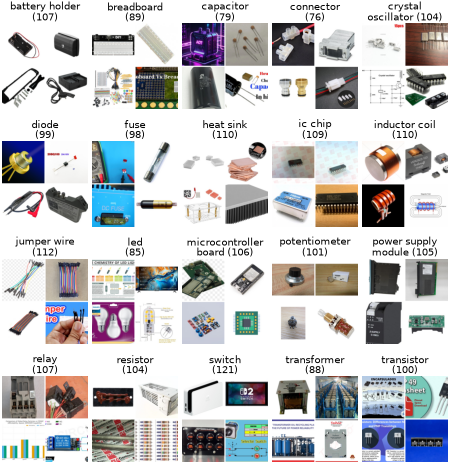

In [6]:
splits = H.load_splits()
fig = H.fig_examples(splits["train"], classes); H.save(fig, "fig02_examples_per_class"); plt.show()

### Train / validation / test split and leakage prevention
The split is fixed and recreated by `tools/export_splits.py` from `data/v2/manifest.json` (no re-randomisation):
the manifest was built with a **cluster-grouped `StratifiedGroupKFold` (seed 42)**: one outer fold became the sealed
**test** set, the remaining development rows were cut into 5 folds. Here **train = development folds 1–4**,
**validation = development fold 0**, **test = the sealed test set**. Because whole near-duplicate clusters are
assigned, no image and no re-encoded copy of an image appears in two splits. The cell below re-checks this from the CSV files.

In [7]:
for a in splits:
    for b in splits:
        if a < b:
            shared_ids = set(splits[a]["id"]) & set(splits[b]["id"])
            shared_clusters = set(splits[a]["cluster"]) & set(splits[b]["cluster"])
            assert not shared_ids and not shared_clusters, (a, b)
print("no shared images or near-duplicate clusters between train / val / test  ✓")
print("seed:", split_info["seed"], "| manifest fingerprint:", split_info["fingerprint"])
sizes = pd.DataFrame({s: [len(d), d["label"].nunique(), int(d["ood_suspect"].sum())] for s, d in splits.items()},
                     index=["images", "classes", "ood_suspect flagged"]).T
sizes["share"] = (sizes["images"] / sizes["images"].sum()).round(3)
display(sizes)
both = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)
display(pd.crosstab(both["label"], both["split"], margins=True)[["train", "val", "test", "All"]])

no shared images or near-duplicate clusters between train / val / test  ✓
seed: 42 | manifest fingerprint: 431315e87d2612cb


,images,classes,ood_suspect flagged,share
train,2010,20,565,0.686
val,502,20,139,0.171
test,418,20,112,0.143


split,train,val,test,All
label,,,,
battery holder,107,26,22,155
breadboard,89,23,19,131
capacitor,79,20,17,116
connector,76,18,16,110
crystal oscillator,104,26,21,151
diode,99,25,21,145
fuse,98,24,20,142
heat sink,110,27,23,160
ic chip,109,26,22,157


## 3. Preprocessing and augmentation
Each model uses the input size and normalisation its weights were trained with (`compclass.models.registry` →
`PreprocessSpec`; `compclass.data.build_transforms`). Every image is decoded to RGB. **Evaluation** (validation, test,
and the feature extraction of C and D): resize the short side to `input_size / crop_pct`, centre-crop `input_size`, scale to
[0, 1], normalise per channel. **Training** (A and B only): `RandomResizedCrop` (random area and aspect ratio),
horizontal flip, `RandAugment` (2 random photometric/geometric ops, magnitude 9), plus mild colour jitter for the
scratch CNN; label smoothing 0.1. Augmentation is applied **only to training batches**.

Why these are realistic: web photos of parts are taken at arbitrary zoom, framing and position (random crops),
components have no canonical left/right orientation (horizontal flip; vertical flips were not used because text and
lighting in product shots have a natural up), and lighting, white balance and JPEG quality vary between shops and
phones (RandAugment's brightness/contrast/colour/sharpness ops, colour jitter). Models C and D are frozen feature extractors
— their features are computed once per image from the evaluation view, so they see no augmentation. D's registered
view resizes the short side to its 256 px input and crops nothing (`crop_pct` 1.0); C keeps timm's 0.9.

In [8]:
from compclass.data import build_transforms
from compclass.models.registry import PreprocessSpec
specs = {n: runs[n]["preprocess"] for n in H.MAIN}
augs = {n: runs[n].get("config", {}).get("aug") for n in H.MAIN}
pre = pd.DataFrame({H.SHORT[n]: {"input size": s["input_size"], "eval resize (short side)": s["resize_short_side"],
                                 "crop_pct": s["crop_pct"], "interpolation": s["interpolation"],
                                 "mean": tuple(round(v, 3) for v in s["mean"]), "std": tuple(round(v, 3) for v in s["std"])}
                    for n, s in specs.items()}).T
display(pre)
for n in H.MAIN:
    sp = PreprocessSpec(**{k: tuple(v) if isinstance(v, list) else v for k, v in specs[n].items() if k != "resize_short_side"})
    print(f"--- {H.SHORT[n]}\n eval : {build_transforms(sp, None, train=False)}")
    if augs[n] is not None:
        print(f" train: {build_transforms(sp, augs[n], train=True)}")

,input size,eval resize (short side),crop_pct,interpolation,mean,std
A: scratch CNN,160,183,0.875,bilinear,"(0.5, 0.5, 0.5)","(0.5, 0.5, 0.5)"
B: ConvNeXt-T (fine-tuned),224,256,0.875,bicubic,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)"
C: SigLIP ViT (frozen + linear),384,427,0.9,bicubic,"(0.5, 0.5, 0.5)","(0.5, 0.5, 0.5)"
D: MobileCLIP2-S3 hybrid (frozen + linear),256,256,1.0,bicubic,"(0.481, 0.458, 0.408)","(0.269, 0.261, 0.276)"


--- A: scratch CNN
 eval : Compose(
    Resize(size=183, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(160, 160))
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
 train: Compose(
    RandomResizedCrop(size=(160, 160), scale=(0.35, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandAugment(num_ops=2, magnitude=9, num_magnitude_bins=31, interpolation=InterpolationMode.BILINEAR, fill=None)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
--- B: ConvNeXt-T (fine-tuned)
 eval : Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
 train: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.5, 1.0), ratio=

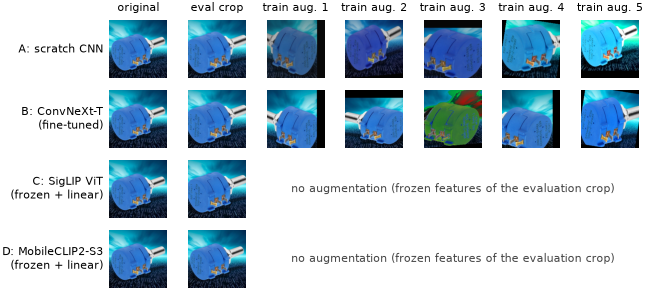

In [9]:
example = H.img_path(splits["train"].query("label == 'potentiometer' and ood_suspect == 0").iloc[3]["path"])
fig = H.fig_augmentation(example, specs, augs); H.save(fig, "fig03_augmentation"); plt.show()

## 4. Models, training and learning curves
**A — custom CNN baseline** (`src/compclass/models/scratch_cnn.py`): stem conv (stride 2) + 4 stages of two
3×3 conv–BatchNorm–ReLU blocks (32→64→128→256 channels, max-pooling between stages), global average pooling, dropout
0.3, linear layer; 1.19 M parameters, He initialisation, **no pretraining**, 160 px input. It shows what can be learned
from ~2k images alone.

**B — ConvNeXt-Tiny, fine-tuned** (Liu et al., 2022; timm `convnext_tiny.fb_in22k_ft_in1k`): a ResNet-style CNN
modernised with 7×7 depthwise convolutions, inverted bottlenecks, LayerNorm and GELU; pretrained on ImageNet-22k and
fine-tuned on ImageNet-1k. **Transfer learning by fine-tuning:** the 1000-class head is replaced by a new 20-class
layer, which is trained alone for the first epoch (so random head gradients do not damage the pretrained features),
then all layers are trained with layer-wise learning-rate decay 0.8 (early, generic layers change least).

**C — SigLIP So400m/14 ViT, frozen + linear head** (Zhai et al., 2023; timm `vit_so400m_patch14_siglip_384.webli`):
a 27-block Vision Transformer (patch 14, width 1152, 384 px) pretrained on WebLI image–text pairs with a sigmoid
contrastive loss. **Transfer learning by feature extraction:** the backbone is frozen; each image is encoded once
(attention-pooled 1152-d embedding), features are standardised with the training-split mean/std, and only a single
`nn.Linear(1152, 20)` (23,060 parameters) is trained with cross-entropy and AdamW. Its weight decay was chosen from
{1e-4, 1e-3, 1e-2, 1e-1} on the validation split.

**D — MobileCLIP2-S3, frozen + linear head** (Faghri et al., 2025; timm `fastvit_mci3.apple_mclip2_dfndr2b`):
a FastViT-MCi3 hybrid, i.e. a convolutional stem and three stages of 38 reparameterisable convolutional (RepMixer)
blocks followed by two stages of 6 self-attention blocks, 122.8 M parameters, 256 px input, pretrained on DFNDR-2B
image–text pairs for on-device use. **Transfer learning by feature extraction, exactly as C:** the backbone is frozen,
each image is encoded once (3072-d pooled feature before the model's text projection), features are standardised with
the training-split mean/std, and only `nn.Linear(3072, 20)` (61,460 parameters) is trained, with the same code, grid
and selection rule as C's head.

**Fairness.** All four models use the same training images, the same validation images for early stopping and model
selection (best epoch by validation macro-F1), and the same test images, scored once. Hyperparameters differ where the
architectures require it (a randomly initialised CNN needs a high LR, many epochs and stronger augmentation; a
pretrained network needs a small LR and few epochs; a linear head on frozen features needs neither augmentation nor
a schedule). A and B use the recipes fixed in the earlier 5-fold cross-validation benchmark (`results/benchmark.csv`)
— nothing was tuned on this test set.

In [10]:
hp = pd.read_csv(H.RES / "hyperparameters.csv")
display(hp.set_index("name").drop(columns="model").T)

name,Custom CNN (scratch),ConvNeXt-T (fine-tuned),SigLIP So400m ViT (frozen + linear),MobileCLIP2-S3 hybrid (frozen + linear)
variant,"width 32, 4 stages, dropout 0.3","ConvNeXt-Tiny, drop_path 0.1","ViT-So400m/14, 384 px, SigLIP (WebLI)","FastViT-MCi3 hybrid, 256 px, MobileCLIP 2 (DFN..."
pretrained_weights,"none (random init, He)",timm convnext_tiny.fb_in22k_ft_in1k (ImageNet-...,timm vit_so400m_patch14_siglip_384.webli (frozen),timm fastvit_mci3.apple_mclip2_dfndr2b (frozen)
input_size,160,224,384,256
batch_size,64,32,256,256
grad_accumulation,1,1,1,1
epochs,"max 200 (ran 200, best epoch 183)","max 20 (ran 20, best epoch 18)","max 200 (ran 34, best epoch 13)","max 200 (ran 31, best epoch 10)"
early_stopping,"val macro-F1, patience 40","val macro-F1, patience 6","val macro-F1, patience 20","val macro-F1, patience 20"
optimiser,AdamW,AdamW,AdamW,AdamW
lr,0.002,0.0002,0.001,0.001
schedule,linear warm-up 5 ep + cosine to 0,linear warm-up 2 ep + cosine to 0; head-only f...,constant,constant


In [11]:
grid = pd.DataFrame(metrics["head_weight_decay_grid"])
display(Markdown("**Model C: weight-decay selection on the validation split** (lr 1e-3, batch 256, ≤200 epochs, "
                 "early stopping patience 20 on validation macro-F1)"))
display(grid)
display(Markdown("**Model D: the same grid on the same validation split** (all four values tie; the pre-set rule keeps the smallest)"))
display(pd.DataFrame(metrics["head_weight_decay_grid_D"]))

**Model C: weight-decay selection on the validation split** (lr 1e-3, batch 256, ≤200 epochs, early stopping patience 20 on validation macro-F1)

,weight_decay,best_epoch,epochs_run,val_macro_f1,val_acc,val_loss,selected
0,0.0001,13,34,0.8011,0.8028,0.7595,True
1,0.0010,13,34,0.8011,0.8028,0.7594,False
2,0.0100,13,34,0.8011,0.8028,0.7594,False
3,0.1000,20,41,0.7999,0.8008,0.7736,False


**Model D: the same grid on the same validation split** (all four values tie; the pre-set rule keeps the smallest)

,weight_decay,best_epoch,epochs_run,val_macro_f1,val_acc,val_loss,selected
0,0.0001,10,31,0.7724,0.7749,0.8995,True
1,0.0010,10,31,0.7724,0.7749,0.8995,False
2,0.0100,10,31,0.7724,0.7749,0.8994,False
3,0.1000,10,31,0.7724,0.7749,0.8979,False


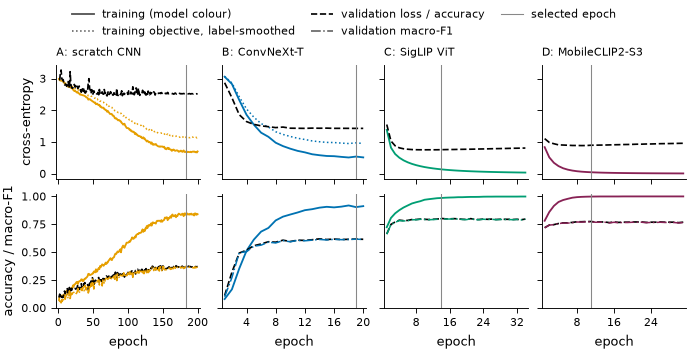

,epochs run,best epoch (1-based),train acc @best,val acc @best,val macro-F1 @best,train CE @best,val CE @best,min val CE (epoch),training time (s)
model,,,,,,,,,
A: scratch CNN,200,184,0.8322,0.3785,0.3737,0.7120,2.5189,2.447 (81),390.3
B: ConvNeXt-T (fine-tuned),20,19,0.9042,0.6175,0.6165,0.5424,1.4311,1.431 (19),120.0
C: SigLIP ViT (frozen + linear),34,14,0.9861,0.8028,0.8011,0.1390,0.7595,0.756 (10),1.7
D: MobileCLIP2-S3 hybrid (frozen + linear),31,11,0.9985,0.7749,0.7724,0.0481,0.8995,0.889 (9),2.4


In [12]:
best = {n: runs[n]["best_epoch"] for n in H.MAIN}
fig = H.fig_learning_curves(histories, best); H.save(fig, "fig04_learning_curves"); plt.show()
rows = []
for n in H.MAIN:
    h = pd.DataFrame(histories[n]); b = best[n]
    rows.append({"model": H.SHORT[n], "epochs run": len(h), "best epoch (1-based)": b + 1,
                 "train acc @best": h.loc[b, "train_acc"], "val acc @best": h.loc[b, "val_acc"],
                 "val macro-F1 @best": h.loc[b, "val_macro_f1"], "train CE @best": h.loc[b, "train_ce"],
                 "val CE @best": h.loc[b, "val_loss"], "min val CE (epoch)": f'{h["val_loss"].min():.3f} ({h["val_loss"].idxmin() + 1})',
                 "training time (s)": runs[n]["train_time_s"]})
display(pd.DataFrame(rows).set_index("model"))

*Reading the curves.* Losses are **plain cross-entropy** for train and validation so they are comparable. For A and B the
training curves are measured on the *augmented* training batches during the epoch (dotted: the label-smoothed
objective that was actually optimised; smoothing puts a floor of ≈0.5 under it). For C and D the training curve is a full
pass over the (un-augmented) training features after each epoch. The grey line marks the epoch whose weights are used
for the test set (also in the legend of the right-hand panels).

**What the curves show.** *A (custom CNN)* improves slowly for most of its 200-epoch budget and is selected at epoch 184. There its training accuracy on augmented batches is 0.83 and its validation accuracy only 0.378. The validation loss is lowest at epoch 81 (2.447; chance level is ln 20 ≈ 3.0) and then rises to 2.519 while validation accuracy and macro-F1 still improve: the network grows more confident without changing many decisions, and 2,010 images are not enough to learn visual features from scratch. *B (ConvNeXt-T)* learns very quickly from the pretrained features: validation accuracy passes 0.5 after 3 epochs and plateaus at about 0.62 from epoch ~9. Training accuracy keeps rising to 0.90–0.91 and validation loss stays flat at about 1.43, which is classic overfitting of a 28 M-parameter network on a small, noisy training set. The cosine schedule and early stopping (best epoch 19 of 20) keep it from getting worse. *C (frozen SigLIP + linear head)* reaches 0.80 validation accuracy within ~5 epochs. Training accuracy goes to 0.99–1.00, because 1,152 standardised features are almost linearly separable for 2,010 images. Validation loss is lowest at epoch 10 (0.756) and then creeps up while validation accuracy/F1 stay flat: the head becomes over-confident without changing many decisions. Early stopping on validation macro-F1 picked epoch 14 (of 34 run). *D (frozen MobileCLIP2-S3 + linear head)* behaves like C one step lower: validation accuracy passes 0.75 in epoch 4 and settles at 0.775, training accuracy reaches 1.00 on 3,072 standardised features, and early stopping picked epoch 11 (of 31 run).

## 5. Evaluation on the held-out test set (418 images, identical for all models)

In [13]:
from compclass.evaluate import extended_metrics
cols = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1",
        "weighted_precision", "weighted_recall", "weighted_f1", "log_loss"]
tab, preds = {}, {}
for n in H.MAIN + H.REFS:
    p = H.load_preds(n); preds[n] = p
    m = extended_metrics(p["y"], p["probs"], classes)
    saved = (metrics["models"].get(n) or metrics["references"][n])["test"]
    assert abs(m["accuracy"] - saved["accuracy"]) < 1e-12 and abs(m["macro_f1"] - saved["macro_f1"]) < 1e-12
    tab[H.SHORT[n]] = {c: m[c] for c in cols}
assert all((preds[n]["ids"] == preds[H.MAIN[0]]["ids"]).all() for n in preds), "same test rows for every model"
tab = pd.DataFrame(tab).T
display(Markdown("**Test metrics** (recomputed here from the saved probabilities; identical to `results/itri626/metrics.json`). "
                 "R1/R2 are reference rows, not additional models: R1 = the same frozen SigLIP features with a "
                 "scikit-learn logistic regression; R2 = the project's deployed model (its head was fit on train + "
                 "validation, i.e. 502 more images). R3 = the packaged Small model: D's frozen "
                 "MobileCLIP2-S3 features with R2's probe + zero-shot recipe, head also fit on train + validation."))
display(tab.style.format("{:.3f}").highlight_max(axis=0, subset=pd.IndexSlice[[H.SHORT[n] for n in H.MAIN], cols[:-1]], props="font-weight:bold"))

**Test metrics** (recomputed here from the saved probabilities; identical to `results/itri626/metrics.json`). R1/R2 are reference rows, not additional models: R1 = the same frozen SigLIP features with a scikit-learn logistic regression; R2 = the project's deployed model (its head was fit on train + validation, i.e. 502 more images). R3 = the packaged Small model: D's frozen MobileCLIP2-S3 features with R2's probe + zero-shot recipe, head also fit on train + validation.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,log_loss
A: scratch CNN,0.400,0.391,0.399,0.391,0.392,0.406,0.400,0.400,2.361
B: ConvNeXt-T (fine-tuned),0.636,0.630,0.642,0.630,0.628,0.644,0.636,0.632,1.346
C: SigLIP ViT (frozen + linear),0.823,0.821,0.827,0.821,0.817,0.831,0.823,0.820,0.614
D: MobileCLIP2-S3 hybrid (frozen + linear),0.773,0.772,0.779,0.772,0.770,0.783,0.773,0.772,0.800
R1: SigLIP + sklearn probe,0.833,0.830,0.838,0.830,0.829,0.842,0.833,0.832,0.606
R2: deployed fused model,0.837,0.836,0.843,0.836,0.834,0.847,0.837,0.836,0.527
R3: Small fused model,0.806,0.804,0.811,0.804,0.802,0.816,0.806,0.806,0.651


In [14]:
# 95% bootstrap intervals (2,000 resamples of the 418 test images) and paired differences between the main models
from sklearn.metrics import f1_score
rng = np.random.default_rng(0)
y = preds[H.MAIN[0]]["y"]; N = len(y)
pred = {n: preds[n]["probs"].argmax(1) for n in H.MAIN}
B = 2000; idx = rng.integers(0, N, (B, N))
boot = {n: {"acc": (pred[n][idx] == y[idx]).mean(1),
            "f1": np.array([f1_score(y[i], pred[n][i], average="macro", labels=range(20), zero_division=0) for i in idx])}
        for n in H.MAIN}
ci = pd.DataFrame({H.SHORT[n]: {"accuracy": (pred[n] == y).mean(),
                                "acc 95% CI": "%.3f-%.3f" % tuple(np.percentile(boot[n]["acc"], [2.5, 97.5])),
                                "macro-F1": f1_score(y, pred[n], average="macro"),
                                "F1 95% CI": "%.3f-%.3f" % tuple(np.percentile(boot[n]["f1"], [2.5, 97.5]))}
                   for n in H.MAIN}).T
display(ci)
from scipy.stats import binomtest
rows = []
for a, b in [("B_convnext_tiny", "A_scratch_cnn"), ("C_siglip_so400m_linear", "B_convnext_tiny"),
             ("C_siglip_so400m_linear", "A_scratch_cnn"),
             ("C_siglip_so400m_linear", "D_mobileclip2_s3_linear"), ("D_mobileclip2_s3_linear", "B_convnext_tiny"),
             ("D_mobileclip2_s3_linear", "A_scratch_cnn")]:
    if a not in pred or b not in pred:   # pairs with D are skipped when WITH_D is False
        continue
    ca, cb = pred[a] == y, pred[b] == y
    n01, n10 = int((~ca & cb).sum()), int((ca & ~cb).sum())
    d = boot[a]["acc"] - boot[b]["acc"]
    rows.append({"comparison": f"{H.SHORT[a]} minus {H.SHORT[b]}", "accuracy difference": ca.mean() - cb.mean(),
                 "95% CI (paired bootstrap)": "%.3f to %.3f" % tuple(np.percentile(d, [2.5, 97.5])),
                 f"only first right": n10, "only second right": n01,
                 "McNemar exact p": binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0})
display(pd.DataFrame(rows).set_index("comparison"))

,accuracy,acc 95% CI,macro-F1,F1 95% CI
A: scratch CNN,0.3995,0.354-0.445,0.3924,0.342-0.432
B: ConvNeXt-T (fine-tuned),0.6364,0.591-0.682,0.6275,0.578-0.668
C: SigLIP ViT (frozen + linear),0.823,0.787-0.859,0.8173,0.774-0.851
D: MobileCLIP2-S3 hybrid (frozen + linear),0.7727,0.732-0.811,0.7703,0.726-0.806


,accuracy difference,95% CI (paired bootstrap),only first right,only second right,McNemar exact p
comparison,,,,,
B: ConvNeXt-T (fine-tuned) minus A: scratch CNN,0.2368,0.189 to 0.289,119,20,2.4362e-18
C: SigLIP ViT (frozen + linear) minus B: ConvNeXt-T (fine-tuned),0.1866,0.141 to 0.232,92,14,3.0602e-15
C: SigLIP ViT (frozen + linear) minus A: scratch CNN,0.4234,0.373 to 0.474,184,7,1.0901e-45
C: SigLIP ViT (frozen + linear) minus D: MobileCLIP2-S3 hybrid (frozen + linear),0.0502,0.014 to 0.086,39,18,7.5082e-03
D: MobileCLIP2-S3 hybrid (frozen + linear) minus B: ConvNeXt-T (fine-tuned),0.1364,0.091 to 0.179,80,23,1.4622e-08
D: MobileCLIP2-S3 hybrid (frozen + linear) minus A: scratch CNN,0.3732,0.325 to 0.423,166,10,1.3448e-37


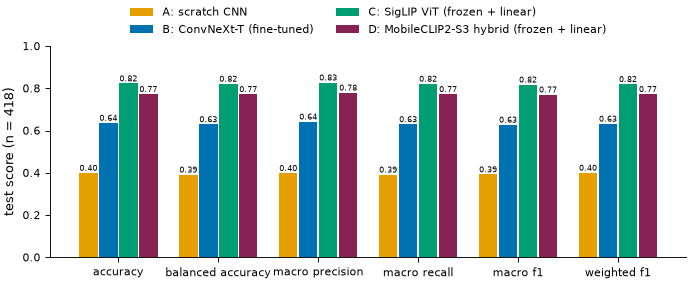

In [15]:
fig = H.fig_test_metrics(pd.DataFrame({n: {k: tab.loc[H.SHORT[n], k] for k in
                         ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]}
                         for n in H.MAIN}).T)
H.save(fig, "fig05_test_metrics"); plt.show()

### Per-class precision, recall and F1 (test set)

In [16]:
pc = pd.read_csv(H.RES / "per_class.csv")
wide = pc.pivot(index="class", columns="model", values=["precision", "recall", "f1"])
wide = wide.reorder_levels([1, 0], axis=1)[[(n, k) for n in H.MAIN for k in ("precision", "recall", "f1")]]
wide.columns = pd.MultiIndex.from_tuples([(H.SHORT[n], k) for n, k in wide.columns])
wide.insert(0, ("", "support"), pc[pc.model == H.MAIN[0]].set_index("class")["support"])
display(wide.style.format("{:.2f}", subset=wide.columns[1:]).background_gradient(cmap="Blues", vmin=0, vmax=1,
                                                                                 subset=wide.columns[1:]))

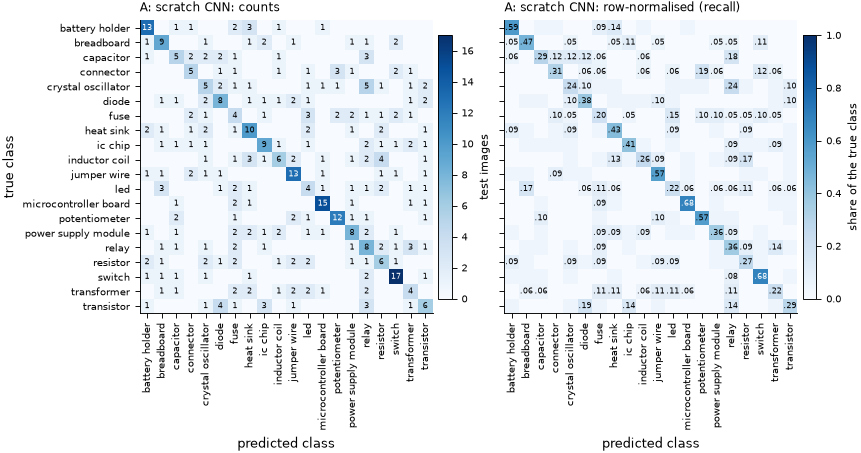

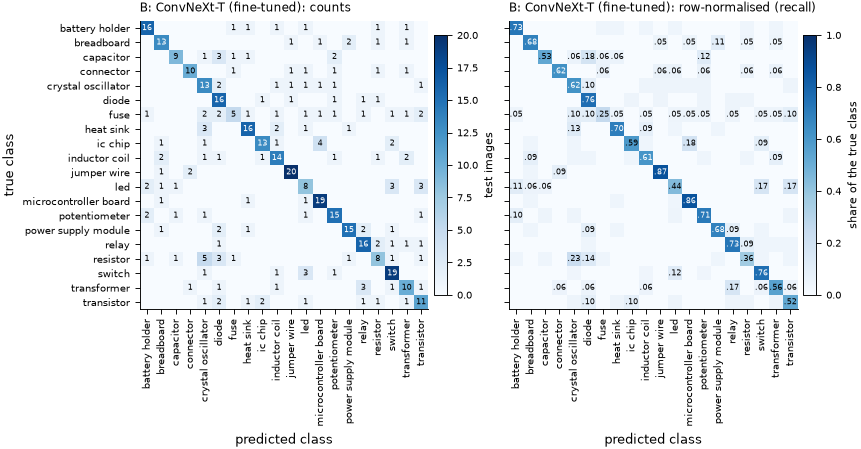

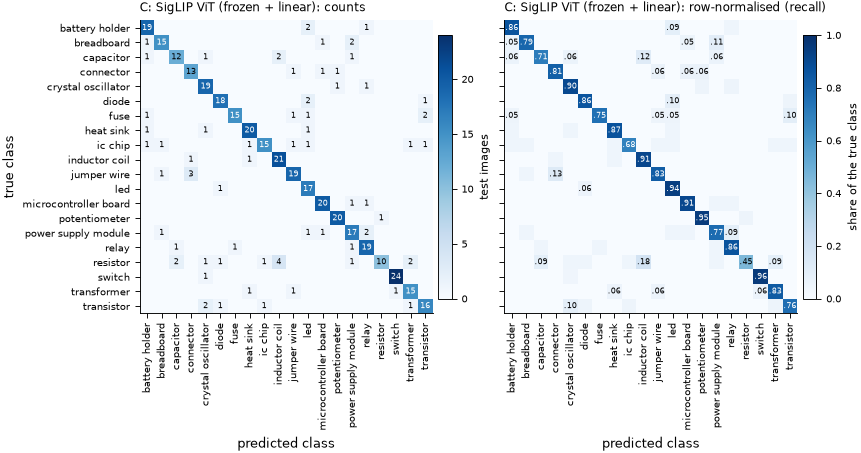

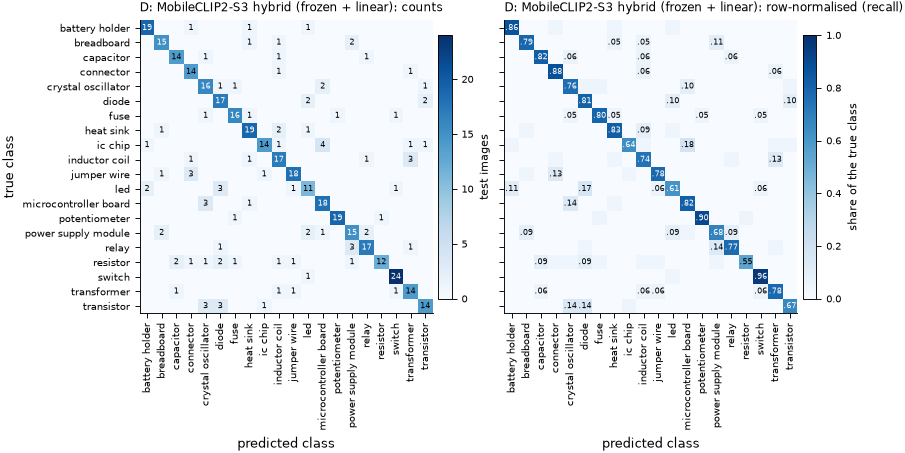

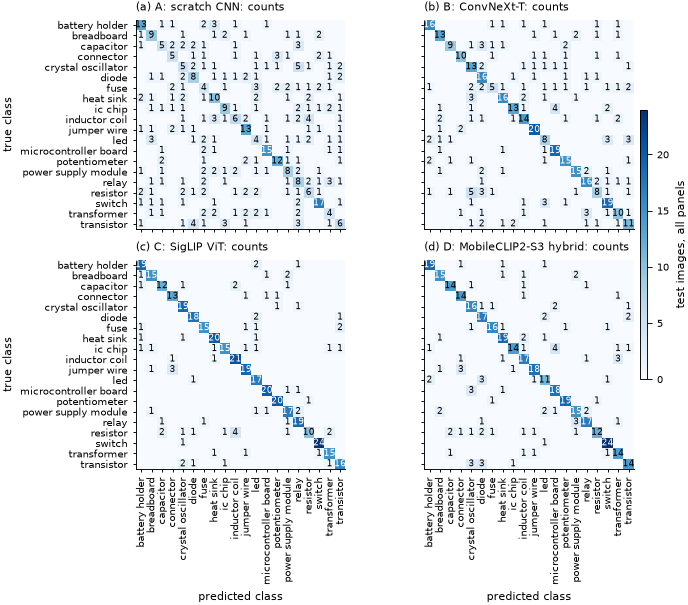

In [17]:
for n in H.MAIN:
    cm = metrics["models"][n]["test"]["confusion"]
    fig = H.fig_confusion(cm, classes, n); H.save(fig, f"fig06_confusion_{n}"); plt.show()
# the report's grid: the four count matrices on one shared colour scale
fig = H.fig_confusion_grid({n: metrics["models"][n]["test"]["confusion"] for n in H.MAIN}, classes)
H.save(fig, "fig06_confusion_grid"); plt.show()

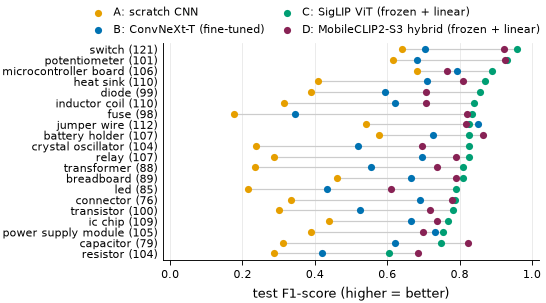

A: scratch CNN: Spearman rho(train images per class, test F1) = +0.51 (p = 0.02)
B: ConvNeXt-T (fine-tuned): Spearman rho(train images per class, test F1) = +0.56 (p = 0.01)
C: SigLIP ViT (frozen + linear): Spearman rho(train images per class, test F1) = +0.43 (p = 0.06)
D: MobileCLIP2-S3 hybrid (frozen + linear): Spearman rho(train images per class, test F1) = +0.20 (p = 0.41)


In [18]:
train_counts = splits["train"]["label"].value_counts()
fig = H.fig_per_class_f1(pc, train_counts); H.save(fig, "fig07_per_class_f1"); plt.show()
from scipy.stats import spearmanr
for n in H.MAIN:
    f = pc[pc.model == n].set_index("class")["f1"]
    r = spearmanr(train_counts[f.index], f)
    print(f"{H.SHORT[n]}: Spearman rho(train images per class, test F1) = {r.statistic:+.2f} (p = {r.pvalue:.2f})")

### Correct and incorrect predictions
For each model: 6 randomly chosen correct predictions and the 6 **most confident** mistakes (the most informative
errors), with true class, predicted class and the softmax confidence of the prediction.

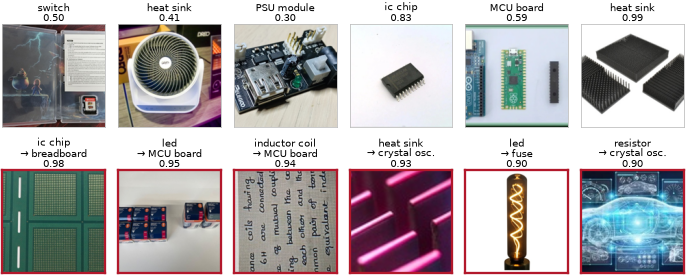

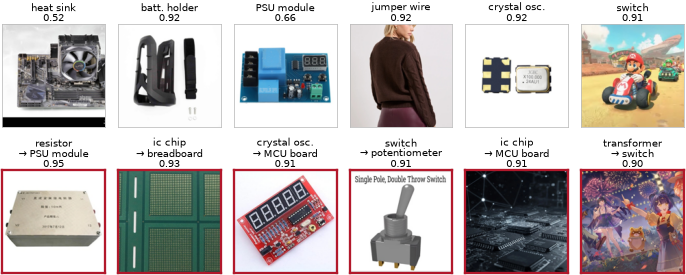

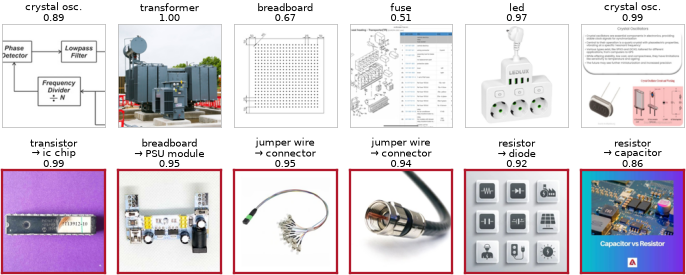

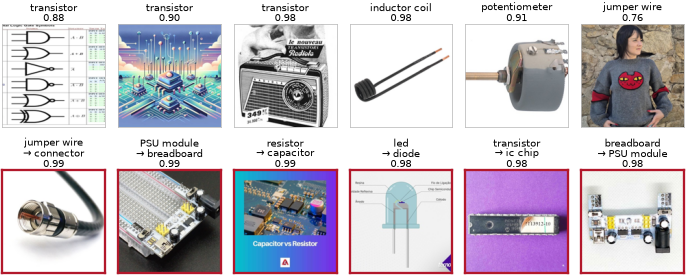

In [19]:
test = splits["test"].set_index("id").loc[preds[H.MAIN[0]]["ids"]].reset_index()
def frame(n):
    p = preds[n]["probs"]
    return pd.DataFrame({"path": test["path"], "true": [classes[i] for i in y], "pred": [classes[i] for i in p.argmax(1)],
                         "conf": p.max(1), "correct": p.argmax(1) == y, "ood": test["ood_suspect"].astype(bool)})
frames = {n: frame(n) for n in H.MAIN}
for k, n in enumerate(H.MAIN):
    f = frames[n]
    ok = f[f.correct].sample(6, random_state=k)
    bad = f[~f.correct].sort_values("conf", ascending=False).head(6)
    fig = H.fig_gallery(pd.concat([ok, bad]), f"{H.SHORT[n]}: 6 random correct (top row) and the 6 most confident errors (bottom row)")
    H.save(fig, f"fig08_gallery_{n}"); plt.show()

### Where the models disagree

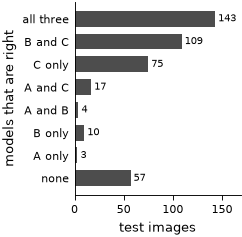

,111,011,001,101,110,010,100,000
test images,143,109,75,17,4,10,3,57


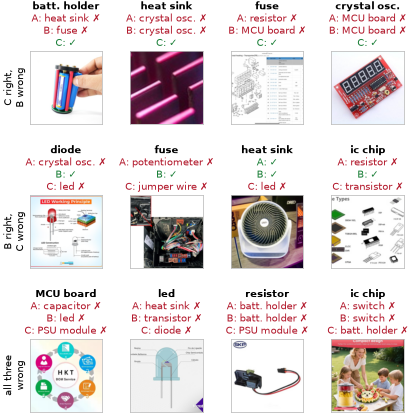

,all four right,all four wrong,"C right, D wrong","D right, C wrong",only D right
test images (with D),140,43,39,18,14


In [20]:
correct = pd.DataFrame({n: frames[n]["correct"] for n in H.MAIN})
fig, counts = H.fig_agreement(correct); H.save(fig, "fig09_agreement"); plt.show()
display(counts.rename("test images").to_frame().T)
dis = pd.DataFrame({"path": test["path"], "true": frames[H.MAIN[0]]["true"], **{n: frames[n]["pred"] for n in H.MAIN}})
pick = pd.concat([dis[correct[H.MAIN[2]] & ~correct[H.MAIN[1]]].sample(4, random_state=0),
                  dis[~correct[H.MAIN[2]] & correct[H.MAIN[1]]].head(4),
                  dis[~correct[H.CORE].any(axis=1)].sample(4, random_state=0)])
fig = H.fig_disagreement(pick, "Disagreements: C right & B wrong (first 4), B right & C wrong (next 4), all three wrong (last 4); x = wrong")
H.save(fig, "fig10_disagreements"); plt.show()
if len(H.MAIN) > 3:
    four = correct[H.MAIN]; Dn, Cn = H.MAIN[3], H.MAIN[2]
    display(pd.Series({"all four right": int(four.all(axis=1).sum()), "all four wrong": int((~four.any(axis=1)).sum()),
                       "C right, D wrong": int((four[Cn] & ~four[Dn]).sum()), "D right, C wrong": int((four[Dn] & ~four[Cn]).sum()),
                       "only D right": int((four[Dn] & ~four[H.CORE].any(axis=1)).sum())}, name="test images (with D)").to_frame().T)

### Most-confused class pairs (true → predicted, test set)

In [21]:
conf_tabs = {H.SHORT[n]: H.most_confused(metrics["models"][n]["test"]["confusion"], classes, 8) for n in H.MAIN}
display(pd.concat(conf_tabs, axis=1))
total = sum(np.asarray(metrics["models"][n]["test"]["confusion"]) for n in H.CORE)
display(Markdown("**Summed over A, B and C:**")); display(H.most_confused(total, classes, 10))

A: scratch CNN                                          B: ConvNeXt-T (fine-tuned)                                                  C: SigLIP ViT (frozen + linear)                             \
                 true      predicted count share_of_true_class                       true              predicted count share_of_true_class                            true            predicted count   
0  crystal oscillator          relay     5               0.238                   resistor     crystal oscillator     5               0.227                        resistor        inductor coil     4   
1          transistor          diode     4               0.190                    ic chip  microcontroller board     4               0.182                     jumper wire            connector     3   
2       inductor coil       resistor     4               0.174                  capacitor                  diode     3               0.176                       capacitor        inductor coil     2   
3           connector  potentiometer     3               0.188                        led                 switch     3               0.167                      breadboard  power supply module     2   
4           capacitor          relay     3               0.176                        led             transistor     3               0.167                            fuse           transistor     2   
5                 led     breadboard     3               0.167                transformer                  relay     3               0.167                           diode                  led     2   
6                fuse            led     3               0.150                   resistor                  diode     3               0.136                      transistor   crystal oscillator     2   
7          transistor        ic chip     3               0.143                  heat sink     crystal oscillator     3               0.130                  battery holder                  led     2   

                      D: MobileCLIP2-S3 hybrid (frozen + linear)                                                   
  share_of_true_class                                       true              predicted count share_of_true_class  
0               0.182                                    ic chip  microcontroller board     4               0.182  
1               0.130                                        led                  diode     3               0.167  
2               0.118                                 transistor     crystal oscillator     3               0.143  
3               0.105                                 transistor                  diode     3               0.143  
4               0.100                      microcontroller board     crystal oscillator     3               0.136  
5               0.095                                      relay    power supply module     3               0.136  
6               0.095                              inductor coil            transformer     3               0.130  
7               0.091                                jumper wire              connector     3               0.130

**Summed over A, B and C:**

,true,predicted,count,share_of_true_class
0,resistor,crystal oscillator,8,0.121
1,transistor,diode,7,0.111
2,jumper wire,connector,7,0.101
3,crystal oscillator,relay,6,0.095
4,transistor,ic chip,6,0.095
5,power supply module,relay,6,0.091
6,heat sink,crystal oscillator,6,0.087
7,connector,potentiometer,5,0.104
8,capacitor,diode,5,0.098
9,transformer,relay,5,0.093


### Effect of data quality: clean vs `ood_suspect`-flagged test images

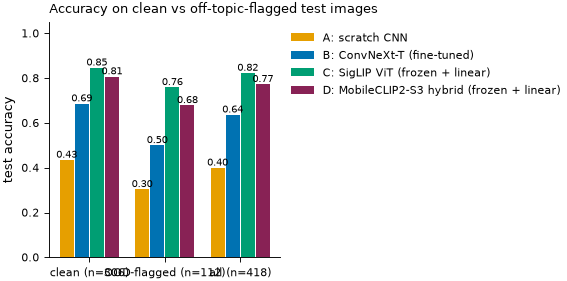

,clean (n=306),OOD-flagged (n=112),all (n=418)
A: scratch CNN,0.4346,0.3036,0.3995
B: ConvNeXt-T (fine-tuned),0.6863,0.5000,0.6364
C: SigLIP ViT (frozen + linear),0.8464,0.7589,0.8230
D: MobileCLIP2-S3 hybrid (frozen + linear),0.8072,0.6786,0.7727


In [22]:
ood = test["ood_suspect"].astype(bool).to_numpy()
q = pd.DataFrame({n: {f"clean (n={int((~ood).sum())})": correct[n][~ood].mean(),
                      f"OOD-flagged (n={int(ood.sum())})": correct[n][ood].mean(),
                      f"all (n={len(ood)})": correct[n].mean()} for n in H.MAIN}).T
fig = H.fig_grouped(q, "Accuracy on clean vs off-topic-flagged test images", "test accuracy")
H.save(fig, "fig11_ood_accuracy"); plt.show()
display(q.rename(index=H.SHORT))

## 6. Model size and inference time

,params,trainable_params,input_size,checkpoint_mb,fp32_weights_mb,gpu_ms_per_image_batch1_fp16,gpu_ms_per_image_batch32_fp16,cpu_ms_per_image_batch1_fp32_8threads,train time (s)
A: scratch CNN,1187636,1187636,160,4.56,4.5,0.52,0.046,1.7,390.3
B: ConvNeXt-T (fine-tuned),27835508,27835508,224,106.24,106.2,2.79,0.803,18.4,120.0
C: SigLIP ViT (frozen + linear),428248660,23060,384,0.10,1633.6,31.10,22.475,893.5,1.7
D: MobileCLIP2-S3 hybrid (frozen + linear),122775668,61460,256,0.26,468.4,15.16,3.098,111.5,2.4


Forward pass of a preprocessed tensor to softmax probabilities, after warm-up; excludes JPEG decode and resizing. C = frozen SigLIP So400m image tower + standardisation + linear head; its checkpoint is only the head (the frozen backbone is the public timm weight file). D = the same with the MobileCLIP2-S3 tower in its inference form (timm reparameterize_model); an entry with a 'machine' field was timed on that machine, the others on the PC in environment.json.


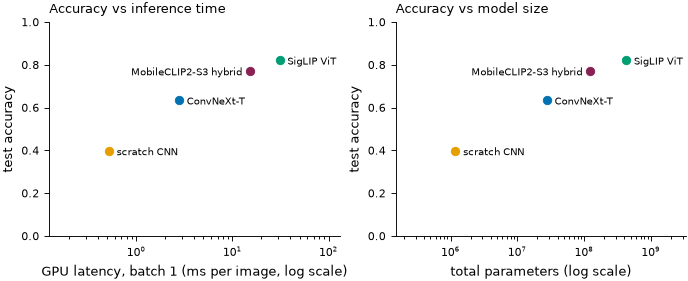

D was timed on a different PC: NVIDIA GeForce RTX 4070 Laptop GPU | C's tower on that PC, same procedure: {'model': "C's tower (SigLIP So400m, no head)", 'input_size': 384, 'gpu_ms_per_image_batch1_fp16': 37.94, 'gpu_ms_per_image_batch32_fp16': 27.877, 'cpu_ms_per_image_batch1_fp32_8threads': 1563.3}


In [23]:
eff = pd.read_csv(H.RES / "efficiency.csv").set_index("model").loc[H.MAIN]
show = eff[["params", "trainable_params", "input_size", "checkpoint_mb", "fp32_weights_mb", "gpu_ms_per_image_batch1_fp16",
            "gpu_ms_per_image_batch32_fp16", "cpu_ms_per_image_batch1_fp32_8threads"]].copy()
show["train time (s)"] = [runs[n]["train_time_s"] for n in show.index]
show.index = [H.SHORT[n] for n in show.index]
display(show)
print(H.load_json(H.RES / "runs" / "profile.json")["_note"])
acc = pd.Series({n: tab.loc[H.SHORT[n], "accuracy"] for n in H.MAIN})
fig = H.fig_efficiency(eff, acc); H.save(fig, "fig12_efficiency"); plt.show()
if len(H.MAIN) > 3:
    mD = H.load_json(H.RES / "runs" / "profile.json")[H.MAIN[3]]["machine"]
    print("D was timed on a different PC:", mD["gpu"], "| C's tower on that PC, same procedure:", mD["c_tower_reference"])

## 7. Interpretation

On the same 418 test images the four families rank clearly. **C (frozen SigLIP So400m ViT + linear head): accuracy 0.823, macro-F1 0.817.** **D (frozen MobileCLIP2-S3 hybrid + linear head): 0.773 / 0.770.** **B (fine-tuned ConvNeXt-T): 0.636 / 0.628.** **A (custom CNN from scratch): 0.400 / 0.392.** The 95 % bootstrap intervals of A (0.35–0.45), B (0.59–0.68) and the two frozen models do not overlap; those of D (0.73–0.81) and C (0.79–0.86) do, and the paired comparison decides between them: C is right where D is wrong on 39 images against 18 the other way (McNemar p = 0.0075; paired-bootstrap gain +0.014 to +0.086), and D beats B on 80 against 23 (p < 1e-7). The other paired comparisons are decisive. B is right where A is wrong on 119 images versus 20 the other way (McNemar p < 1e-17). C beats B on 92 images versus 14 (p < 1e-14), and the paired-bootstrap accuracy gain of C over B is +0.14 to +0.23. Balanced accuracy and macro/weighted averages tell the same story because the classes are nearly balanced. Every model's test score is 1.5–2.5 points above its validation score at the chosen epoch, which is ordinary sampling variation between two ~450-image sets; the test set was not used for any choice. The reference rows agree with model C. A scikit-learn logistic regression on the same features (R1) gives 0.833 / 0.829, a difference of 4 images, which is within noise. The project's deployed model (R2, the same backbone with a probe head fit on train + validation and fused with the zero-shot text head) gives 0.837 / 0.834, so C is a faithful, slightly cheaper reproduction of the deployed model. R3, the packaged Small model (D's features with R2's recipe), gives 0.806 / 0.802: the same fused recipe lifts D by about three points, as it lifts C by one.

### Why the models differ

The ranking follows **how much relevant visual knowledge each model brings to a 2,010-image problem**, not architecture depth alone. (1) *A* starts from random weights. With ~100 web images per class it must learn edges, textures, part shapes and the classes at once, and its validation curve shows it is data-limited. Its per-class F1 also correlates with the number of training images (Spearman ρ = 0.51 over the 20 classes, versus 0.56 for B and 0.43 for C). Section 8 shows that, apart from training it to convergence, no recipe change moved it. (2) *B* re-uses ImageNet-22k features, which already encode generic objects, materials and shapes, so it reaches 0.6 within a few epochs. Fine-tuning 28 M parameters on 2k noisy images then overfits: training accuracy is 0.9 versus 0.62 on validation. ImageNet also has few classes for electronic parts, so the features are generic rather than specific. (3) *C* uses a 400 M-parameter ViT pretrained on billions of web image–text pairs (WebLI). Its embedding already separates concepts like "resistor" and "capacitor" and is robust to the photo, render, diagram and stock-image mix of this dataset, which comes from the same web domain. Keeping the backbone frozen and training only 23,060 parameters means it cannot overfit the backbone to label noise. It also makes training almost free (1.7 s for all four weight-decay runs on cached features), but inference is about 11× slower than B on the GPU (31 vs 2.8 ms per image at batch 1). The weight-decay grid shows that for C the regularisation that matters is early stopping, not weight decay: 1e-4, 1e-3 and 1e-2 gave the identical best epoch and validation F1 (0.801), because AdamW's decoupled decay of lr × wd per step is negligible over ~30 epochs. The smallest value was kept by the pre-set tie-break. (4) *D* applies C's strategy with a backbone built for phones: a 123 M-parameter convolution–attention hybrid pretrained on 2 billion image–text pairs. Its frozen features are less separating than C's (test accuracy 0.773 against 0.823), but far better than fine-tuned ImageNet features (B, 0.636), which says the pretraining data and objective matter more than the architecture family or its size: the smaller web-pretrained hybrid beats the larger-capacity fine-tune by 13.6 points. On the same PC it is 2.5× faster than C's tower at batch 1 on the GPU, 9× at batch 32 and 14× on the CPU.

### Important errors

*Important errors.* (1) **Look-alike components.** C's most frequent confusions are resistor → inductor coil, jumper wire → connector, and resistor → transformer / capacitor. B's are resistor → crystal oscillator and ic chip → microcontroller board. D's are ic chip → microcontroller board, inductor coil → transformer, jumper wire → connector and led → diode, the same look-alike families. These classes share shapes (axial bodies with leads, cables with plugs, chips on boards). Resistor is C's weakest class (F1 0.61) and fuse is B's (0.34). (2) **Images that do not show the labelled object.** Many of the most confident errors are pictures of something else. Examples: an icon sheet labelled *resistor* (C says diode), a *Capacitor vs Resistor* banner, a breadboard power module labelled *breadboard*, a fibre-optic pigtail and a coax plug labelled *jumper wire* (C says connector, arguably correctly), and a DIP chip labelled *transistor*. All three of A, B and C fail on 57 test images (43 when D is counted too), many of them infographics, diagrams or scenes with no component. (3) **Data quality dominates the remaining errors.** On the 306 test images not flagged as off-topic, accuracy is A 0.435, B 0.686, C 0.846, D 0.807. On the 112 flagged images it is 0.304, 0.500, 0.759 and 0.679. The contamination costs B the most (−19 points) and C the least (−9 points), because C's pretraining has seen such web content. (4) **Confidence is informative.** C's mean confidence is 0.87 on correct and 0.47 on wrong predictions, so a reject option (as in the deployed model's 0.5 threshold) can catch many errors. The gallery shows that its most confident errors (0.86–0.99) are mostly label or scope problems rather than model mistakes. Class imbalance is not an important factor here: the largest/smallest class ratio is ~1.6 and per-class F1 is not ordered by class size for C (p = 0.06).

### Limitations

*Limitations.* (1) **One split, one seed.** The test set has 418 images (~21 per class), so per-class F1 values move by ±0.1 with a single image, and model differences under ~4 points would not be significant. The 5-fold cross-validation benchmark in `results/benchmark.csv` gives the same ordering with fold-to-fold standard deviations of 1.2–3.4 macro-F1 points (scratch CNN 1.5, ConvNeXt-T 3.4, SigLIP So400m probe 1.2). The scratch-CNN run is not bit-reproducible on the GPU (cuDNN autotuning): with the identical config and seed, two fold-0 runs of A's recipe reached validation macro-F1 0.402 and 0.374 (section 8), while ConvNeXt reproduced exactly (0.6175). (2) **Noisy labels.** Labels are image-search terms that were not relabelled by hand. Some test labels are themselves wrong or ambiguous, and 27 % of test images are flagged as possibly off-topic, so the measured accuracy is an underestimate for clean photos and an overestimate of usefulness on real workbench photos. (3) **Different training budgets.** A ran 200 epochs (lengthened from 120 after the improvement study of section 8, on development folds only) and B 20; neither was tuned exhaustively. C's backbone was trained by Google on far more data than the other two, so the comparison measures *transfer-learning strategies as available to a student*, not architectures in isolation. (4) **Compute.** C is 428 M parameters (1.6 GB in fp32) and needs ~0.9 s per image on an 8-thread CPU, versus 18 ms for B and 1.7 ms for A, which matters for an embedded or real-time application. (5) **Model D's two asymmetries.** D was timed on a different PC than A–C (an RTX 4070 laptop; C's tower was re-timed there with the same procedure as the anchor for every C-to-D ratio), and its evaluation view keeps the whole short side (crop fraction 1.0) while C keeps timm's 0.9; on the development folds that view is worth about 1.5 points to C (`docs/EFFICIENCY_STUDY.md`), so the C-to-D gap is, if anything, understated. MobileCLIP 2's weights carry Apple's research-only licence, unlike SigLIP's Apache-2.0.

### Conclusion and recommended model

**Recommended model: C, the frozen SigLIP So400m ViT with a linear softmax head** (test accuracy 0.823, macro-F1 0.817). It is the most accurate by a wide, statistically clear margin, the most robust to off-topic web images, and the cheapest to train: only 23 k parameters are learned, in seconds, once the features are extracted. It is well calibrated enough for a reject option. Use it where a GPU, or ~1 s per image on CPU, is acceptable. Where C is too heavy, **D is the second choice**: 0.773 accuracy with 3.5× fewer parameters, 2.5× faster on the GPU at batch 1 and 14× faster on the CPU (about 0.11 s per image), 5.0 points below C and 13.6 above B, for non-commercial use only under its weights' licence. If inference cost matters most (a microcontroller board, real-time video on a CPU), ConvNeXt-T fine-tuning is the practical third choice: 11× faster on GPU and 49× faster on CPU, at about 19 accuracy points lower. Training a CNN from scratch is not competitive at this data size and serves only as the baseline that shows the value of transfer learning: +24 points from ImageNet fine-tuning, and a further +19 points from large-scale image–text pretraining. Section 8 shows that the scratch network cannot be tuned out of that position: training to convergence gained 3.5 points on the development folds, nothing else in architecture, regularisation or initialisation gained anything, and the only further gain came from distilling model C's predictions. The clearest route to further gains is better data (relabelling the audited issues and the homonym-contaminated classes such as *switch* and *transformer*), not a bigger model.

## 8. Improving model A (development folds; one test look; one holdout look)

A 24-experiment study (`docs/SCRATCH_CNN_IMPROVEMENT_REPORT.md`, log in `docs/SCRATCH_CNN_IMPROVEMENT_LOG.md`) asked
whether a better recipe would close the scratch CNN's gap. Every change was screened on development folds 0–2 and
confirmed on all five; single-run noise is ±2–3 macro-F1 points. Input resolution, MixUp, width, depth, residual
blocks, label smoothing, flip TTA, whitening/identity initialisation, stronger augmentation, dropout 0.5, weight
averaging and whole-picture resizing changed nothing or made it worse. Two things helped:

* **Training to convergence** (200 instead of 120 epochs): +3.5 points of five-fold macro-F1, better on every fold.
  This is the model A used in this notebook and the report.
* **Knowledge distillation from model C's features** (a logistic probe on frozen SigLIP features, fitted per fold on
  that fold's training rows only; loss `0.1·CE + 0.9·2²·KL(teacher/2 ‖ student/2)`, 300 epochs): a further
  +4.6 ± 0.7 points on every fold. It brings C's pretrained knowledge in through the targets, so it is a fourth model,
  not a better A.

Both final recipes were then trained once on this notebook's fixed split and scored once on the 418 test images and
once on the 407 Wikimedia holdout photographs (the deployed SigLIP model's out-of-source test, never used for training).
The table below is built from the saved files; nothing is retrained here.

In [24]:
import json
from pathlib import Path

def five_fold(path, h):
    recs = {}
    for ln in Path(path).read_text().splitlines():
        if ln.strip():
            r = json.loads(ln)
            if r["config_hash"] == h:
                recs.setdefault(r["fold"], r["macro_f1"])   # first run per fold = the five-fold confirmation
    f = np.array([recs[k] for k in range(5)]); return f

IMPR = H.ROOT / "results" / "scratch_cnn_improvement"
ld = lambda p: json.loads(Path(p).read_text())
f_old = five_fold(H.ROOT / "results/phase2/runs_fixed.jsonl", "4e4c6e8f6cf3")
f_200 = five_fold(H.ROOT / "results/runs_win.jsonl", "b0afa2aa4d60")
f_kd = five_fold(H.ROOT / "results/runs_win.jsonl", "fbe64b2765cb")
t200, tkd = ld(IMPR / "test_plain_200ep_b0afa2aa4d60_fold0.json"), ld(IMPR / "test_distill_300ep_fbe64b2765cb_fold0.json")
h200, hkd = ld(IMPR / "web_holdout_plain_200ep_b0afa2aa4d60.json"), ld(IMPR / "web_holdout_distill_300ep_fbe64b2765cb.json")
wh = ld(H.ROOT / "results/final/final_test_web_holdout_v1.json")
assert abs(t200["macro_f1"] - metrics["models"]["A_scratch_cnn"]["test"]["macro_f1"]) < 1e-12  # the A of this notebook
rows = [
    ("A, previous build (120 ep)", f_old, (0.3361, 0.3541), None),
    ("A, this notebook (200 ep)", f_200, (t200["macro_f1"], t200["accuracy"]), (h200["macro_f1"], h200["accuracy"])),
    ("A + distillation from C (300 ep)", f_kd, (tkd["macro_f1"], tkd["accuracy"]), (hkd["macro_f1"], hkd["accuracy"])),
]
tab = pd.DataFrame([{"recipe": n, "dev 5-fold macro-F1": f"{f.mean():.3f} ± {f.std(ddof=1):.3f}",
                     "per fold": " ".join(f"{x:.3f}" for x in f),
                     "test macro-F1": t[0], "test acc": t[1],
                     "holdout macro-F1": (h[0] if h else np.nan), "holdout acc": (h[1] if h else np.nan)} for n, f, t, h in rows]
                   + [{"recipe": "deployed SigLIP model (R2)", "dev 5-fold macro-F1": "", "per fold": "",
                       "test macro-F1": metrics["references"]["R2_deployed_fused"]["test"]["macro_f1"],
                       "test acc": metrics["references"]["R2_deployed_fused"]["test"]["accuracy"],
                       "holdout macro-F1": wh["macro_f1"], "holdout acc": wh["accuracy"]}]).set_index("recipe")
display(tab.round(4))
d = f_kd - f_200
s_test = ld(IMPR / "summary.json")["paired_bootstrap_2000_kd_minus_plain"]
s_hold = ld(IMPR / "web_holdout_summary.json")["paired_bootstrap_2000_kd_minus_plain"]
print(f"distillation - plain, five dev folds: {100*d.mean():+.1f} ± {100*d.std(ddof=1)/np.sqrt(5):.1f} points, better on {int((d>0).sum())}/5")
print(f"distillation - plain, test (418, paired bootstrap): {100*s_test['macro_f1_mean']:+.1f} points, 95% CI [{100*s_test['macro_f1_ci95'][0]:+.1f}, {100*s_test['macro_f1_ci95'][1]:+.1f}]")
print(f"distillation - plain, holdout (407, paired bootstrap): {100*s_hold['macro_f1_mean']:+.1f} points, 95% CI [{100*s_hold['macro_f1_ci95'][0]:+.1f}, {100*s_hold['macro_f1_ci95'][1]:+.1f}]")

,dev 5-fold macro-F1,per fold,test macro-F1,test acc,holdout macro-F1,holdout acc
recipe,,,,,,
"A, previous build (120 ep)",0.355 ± 0.015,0.334 0.376 0.348 0.360 0.357,0.3361,0.3541,NaN,NaN
"A, this notebook (200 ep)",0.390 ± 0.007,0.402 0.390 0.387 0.383 0.390,0.3924,0.3995,0.2570,0.2826
A + distillation from C (300 ep),0.436 ± 0.011,0.425 0.428 0.434 0.442 0.451,0.3933,0.4115,0.2976,0.3170
deployed SigLIP model (R2),,,0.8337,0.8373,0.8159,0.8206


distillation - plain, five dev folds: +4.6 ± 0.7 points, better on 5/5


distillation - plain, test (418, paired bootstrap): +0.1 points, 95% CI [-4.4, +4.5]
distillation - plain, holdout (407, paired bootstrap): +4.0 points, 95% CI [+0.3, +7.9]


**Reading.** The schedule gain carries over to the test split (+5.6 points over the previous build). The distillation
gain does not show on the single test look (+0.1 points, interval about ±4.5: 418 images cannot resolve a 4-point
difference between two single training runs), but it reappears on the out-of-source photographs (+4.0 points, interval
excluding zero). Source shift is where the from-scratch network really loses: a third of its score, against 2 points
for the deployed pretrained model on the same photographs. Features learned from 2,010 photographs of one web scrape
describe that scrape; the only lever that moved the scratch network, apart from letting it finish training, was a
pretrained model's knowledge.

In [25]:
print("figures written to", H.FIG.relative_to(H.ROOT))
print(sorted(p.name for p in H.FIG.glob("*.png")))

figures written to results\itri626\figures_four_models
['fig01_class_counts.png', 'fig02_examples_per_class.png', 'fig03_augmentation.png', 'fig04_learning_curves.png', 'fig05_test_metrics.png', 'fig06_confusion_A_scratch_cnn.png', 'fig06_confusion_B_convnext_tiny.png', 'fig06_confusion_C_siglip_so400m_linear.png', 'fig06_confusion_D_mobileclip2_s3_linear.png', 'fig06_confusion_grid.png', 'fig07_per_class_f1.png', 'fig08_gallery_A_scratch_cnn.png', 'fig08_gallery_B_convnext_tiny.png', 'fig08_gallery_C_siglip_so400m_linear.png', 'fig08_gallery_D_mobileclip2_s3_linear.png', 'fig09_agreement.png', 'fig10_disagreements.png', 'fig11_ood_accuracy.png', 'fig12_efficiency.png']
